## Análisis descriptivo de las noticias

Análisis descriptivo de las noticias para identificación de emojis, caracteres extraños, palabras extrañas, ortografía y pérdida de contexto ante limpiezas habituales.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Markdown, display

raiz = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(raiz))

from src.analisis_texto import (
    Analizador_Detonantes, Analizador_Emojis, Analizador_Impacto_Limpieza,
    Analizador_Palabras_Raras, AnalizadorOrtografia, Carga_Corpus,
    Inventario_Caracteres, Perfilador_Textos, palabra_en_contexto,
)

ruta_datos = raiz / "data" / "interim" / "noticias_unidas_local.csv"
idiomas = ["en", "es"]
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 200)

In [2]:
def titulo(texto):
    display(Markdown(f"## {texto}"))


def seccion_caracteres(df):
    titulo("1. Inventario de caracteres y caracteres raros")
    inventario = Inventario_Caracteres(df["texto"])
    display(inventario.resumen_por_tipo())
    for tipo in ["mojibake_c1", "simbolo_raro", "simbolo_dingbat", "control_o_invisible", "espacio_raro", "letra_otro_alfabeto"]:
        tabla = inventario.por_tipo(tipo, top=15)
        if not tabla.empty:
            display(Markdown(f"**{tipo}** (top 15)"))
            display(tabla.reset_index(drop=True))
    return inventario


def seccion_perfil(df, inventario):
    titulo("2. Perfil por documento (por label y por fuente)")
    perfil = Perfilador_Textos(inventario.caracteres_raros()).perfilar(df)
    display(Markdown("**Por label**"))
    display(Perfilador_Textos.prevalencia(perfil, "label"))
    display(Markdown("**Por fuente**"))
    display(Perfilador_Textos.prevalencia(perfil, "fuente"))
    return perfil


def seccion_emojis(df):
    titulo("3. Emojis")
    emojis = Analizador_Emojis(df)
    display(emojis.top(15))
    display(emojis.por_grupo("fuente"))
    display(emojis.por_grupo("label"))


def seccion_palabras_raras(df):
    titulo("4. Palabras raras")
    analizador = Analizador_Palabras_Raras(df, muestra=10000)
    display(analizador.resumen())
    for regla in analizador.reglas:
        display(Markdown(f"**{regla}**: " + ", ".join(f"`{p}`" for p in analizador.ejemplos(regla, 12))))


def seccion_detonantes(df):
    titulo("5. Posibles palabras detonantes (sin eliminar stop words)")
    display(Markdown(
        "`log_odds` > 0 apunta a **label 1**, < 0 a **label 0**. "
        "Si `pct_fuente` es alto (≈100), la palabra delata la *fuente*, no el contenido: **riesgo de fuga**."))
    analizador = Analizador_Detonantes(min_df=20)
    resultados = {}
    for idioma in df["idioma"].unique():
        hacia_1, hacia_0 = analizador.ajustar(df, idioma, top=20)
        resultados[idioma] = (hacia_1, hacia_0)
        display(Markdown(f"### Idioma `{idioma}` — hacia label 1"))
        display(hacia_1)
        display(Markdown(f"### Idioma `{idioma}` — hacia label 0"))
        display(hacia_0)
    return resultados


def seccion_contexto(df, resultados):
    titulo("6. Contexto: ¿cómo se usan los detonantes y qué perdería una limpieza?")
    for idioma in resultados:
        hacia_1, hacia_0 = resultados[idioma]
        for palabra in list(hacia_1["palabra"].head(3)) + list(hacia_0["palabra"].head(3)):
            display(Markdown(f"**[{idioma}] `{palabra}`**"))
            for fragmento in palabra_en_contexto(df.loc[df["idioma"] == idioma, "texto"], palabra, n=3):
                print("  -", fragmento)
    display(Markdown("### Impacto de limpiezas típicas (muestra de 2.500 textos)"))
    display(Analizador_Impacto_Limpieza(df).ejecutar())


def seccion_ortografia(df):
    titulo("7. Ortografía")
    analizador = AnalizadorOrtografia(muestra_por_idioma=5000)
    if not analizador.tiene_corrector:
        display(Markdown("> `pyspellchecker` no está instalado: se usa el método de respaldo (hapax)."))
    for idioma in df["idioma"].unique():
        stats, tabla = analizador.analizar(df, idioma)
        display(Markdown(f"**{idioma}**: {stats}"))
        display(tabla.T)
        display(analizador.por_label(df, idioma))


def graficar(perfil):
    titulo("8. Gráficas")
    fig, ejes = plt.subplots(1, 3, figsize=(16, 4))
    for eje, columna in zip(ejes, ["n_chars", "pct_mayus", "n_exclam"]):
        for etiqueta, grupo in perfil.groupby("label"):
            eje.hist(grupo[columna].clip(upper=grupo[columna].quantile(0.99)), bins=40, alpha=0.5,
                     label=f"label {etiqueta}")
        eje.set_title(columna)
        eje.legend()
    plt.tight_layout()
    plt.show()

{'filas_leidas': 54376,
 'vacios': 667,
 'duplicados': 5902,
 'duplicados_label_distinto': 0,
 'filas_finales': 47807}

**47,807 textos** · idiomas: {'en': 44703, 'es': 3104} · labels: {0: 25749, 1: 22058}

# Idioma: `es` · 3,104 textos · labels: {0: 1569, 1: 1535}

## 1. Inventario de caracteres y caracteres raros

,distintos,total,pct_total
tipo,,,
letra_latina,52,3510371,78.3199
espacio,1,721506,16.0975
puntuacion_comun,38,110770,2.4714
letra_latina_acentuada,39,84467,1.8845
salto_o_tab,2,37124,0.8283
digito,10,16130,0.3599
letra_otro_alfabeto,77,1440,0.0321
simbolo_raro,18,108,0.0024
emoji,17,95,0.0021


**simbolo_raro** (top 15)

... (52 outputs left out)

**es**: {'idioma': 'es', 'metodo': 'pyspellchecker', 'docs_muestra': 3104, 'vocabulario': 36044, 'desconocidas': 24304, 'pct_desconocidas': 67.43}

,0,1,2,3,4,5,6,7,8,9,...,15,16,17,18,19,20,21,22,23,24
palabra,han,años,fue,está,personas,dijo,tiene,hay,todos,puede,...,otros,mujeres,había,días,será,tienen,qué,coronavirus,sea,casos
frecuencia,1303,1286,1254,1186,989,815,783,762,743,703,...,533,509,501,480,479,434,396,375,371,370


,idioma,metodo,docs_muestra,vocabulario,desconocidas,pct_desconocidas
label,,,,,,
0,es,pyspellchecker,1569,26569,16951,63.80
1,es,pyspellchecker,1535,23333,15123,64.81


## 8. Gráficas

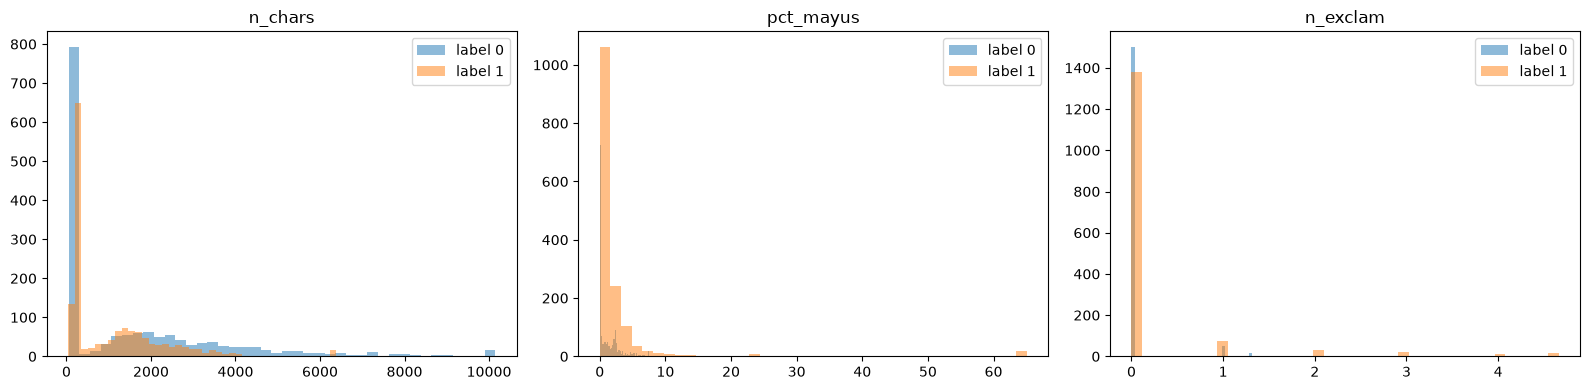

# Idioma: `en` · 44,703 textos · labels: {0: 24180, 1: 20523}

## 1. Inventario de caracteres y caracteres raros

,distintos,total,pct_total
tipo,,,
letra_latina,52,99607753,79.9097
espacio,1,20732675,16.6327
puntuacion_comun,44,3177260,2.5489
digito,12,788872,0.6329
salto_o_tab,3,318087,0.2552
espacio_raro,6,17136,0.0137
mojibake_c1,18,2809,0.0023
letra_otro_alfabeto,86,2043,0.0016
letra_latina_acentuada,54,1605,0.0013


**mojibake_c1** (top 15)

,caracter,codepoint,nombre,tipo,conteo
0,\x92,U+0092,C1 (cp1252 → ’),mojibake_c1,1280
1,\x94,U+0094,C1 (cp1252 → ”),mojibake_c1,392
2,\x93,U+0093,C1 (cp1252 → “),mojibake_c1,386
3,\x96,U+0096,C1 (cp1252 → –),mojibake_c1,163
4,\x80,U+0080,C1 (cp1252 → €),mojibake_c1,137
5,\x97,U+0097,C1 (cp1252 → —),mojibake_c1,137
6,\x9d,U+009D,C1 (sin equivalente cp1252),mojibake_c1,129
7,\x91,U+0091,C1 (cp1252 → ‘),mojibake_c1,59
8,\x99,U+0099,C1 (cp1252 → ™),mojibake_c1,42
9,\x9c,U+009C,C1 (cp1252 → œ),mojibake_c1,39


**simbolo_raro** (top 15)

... (52 outputs left out)

**en**: {'idioma': 'en', 'metodo': 'pyspellchecker', 'docs_muestra': 5000, 'vocabulario': 30452, 'desconocidas': 3010, 'pct_desconocidas': 9.88}

,0,1,2,3,4,5,6,7,8,9,...,15,16,17,18,19,20,21,22,23,24
palabra,doesn,didn,isn,wasn,couldn,aren,wouldn,cyber,pre,hasn,...,shouldn,weren,org,fjs,screengrab,jihadist,facto,alt,jihadists,superdelegates
frecuencia,548,497,287,211,151,137,126,116,106,92,...,61,61,58,57,53,44,43,39,39,38


,idioma,metodo,docs_muestra,vocabulario,desconocidas,pct_desconocidas
label,,,,,,
0,en,pyspellchecker,5000,26045,1210,4.65
1,en,pyspellchecker,5000,32186,4033,12.53


## 8. Gráficas

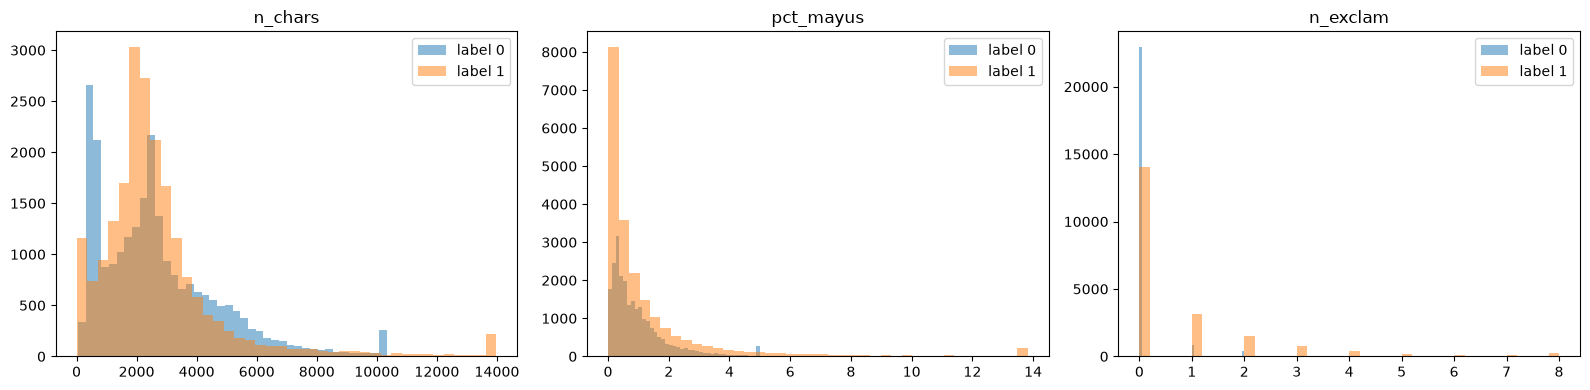

In [3]:

def main():
    carga = Carga_Corpus(ruta_datos)
    df = carga.cargar()
    display(carga.reporte)
    display(Markdown(f"**{len(df):,} textos** · idiomas: {df['idioma'].value_counts().to_dict()} "
                     f"· labels: {df['label'].value_counts().to_dict()}"))
    for idioma in ["es", "en"]:                      # español primero: es el del modelo A
        d = df[df["idioma"] == idioma].reset_index(drop=True)
        display(Markdown(f"# Idioma: `{idioma}` · {len(d):,} textos · labels: {d['label'].value_counts().to_dict()}"))
        inventario = seccion_caracteres(d)
        perfil = seccion_perfil(d, inventario)
        seccion_emojis(d)
        seccion_palabras_raras(d)
        resultados = seccion_detonantes(d)
        seccion_contexto(d, resultados)
        seccion_ortografia(d)
        graficar(perfil)

main()